# Supergranulation with the dopplergrams of Haywood et al. (2016), rotation fitted every day: one good and one bad day

In [1]:
import os, json, shutil, tempfile, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from argparse import Namespace
from sunsim import local_path, sdo, observations as obs, supergranulation as sg

DAYS = {'2021-05-25': 'good: old r = 0.90', '2021-05-15': 'bad: old r = 0.13'}   # RV, per_day_table of the quality run
OUT = str(local_path('supergranulation_haywood_results'))   # days/ and results/ of PIC/supergranulation_haywood.py
TABLE1_RESULTS = 'results_2days_quality_0.99'               # the run with the rotation of Table 1 (if it is there)
DIFF_EXTINCTION = True                                      # HARPS-N RV minus rv_diff_extinction of the release
EXT = '_diffext' if DIFF_EXTINCTION else ''                 # results with it in their own folders
RESULTS = 'results_2days_rotfit%s_quality_0.99' % EXT
VARIANTS = {                                                # label: results folder, options of collect, colour
    'disc mean removed': ('results_2days_rotfit_discmean%s_quality_0.99' % EXT, dict(remove_disc_mean=True), '#2f7d32'),
    'a1 + a4 OBS_VR': ('results_2days_rotvr%s_quality_0.99' % EXT, dict(rotation_obs_vr=True), '#3b6fb6'),
    'a1 + a4 OBS_VR, CLV(OBS_VR) - average': ('results_2days_rotvr_clv5vr%s_quality_0.99' % EXT,
                                              dict(rotation_obs_vr=True, clv_deg=5, clv_drift='obs_vr', drift_deg=2), '#e7298a'),
    'a1 + a4 OBS_VR, CLV(OBS_VR, 24 h, 12 h) - average': ('results_2days_rotvr_clv5vr_h2%s_quality_0.99' % EXT,
                                                       dict(rotation_obs_vr=True, clv_deg=5, clv_drift='obs_vr', drift_deg=2,
                                                            drift_harmonics=2), '#e4572e')}
START = '2021-05-01'
N_RINGS = 30
WINDOW = 720.0                                              # [s] 45 s dopplergrams averaged around every exposure
MU_MIN = 0.1
MIN_OBS_QUALITY = 0.99
MIN_DAY_EXP = 50
THRESHOLDS = dict(noise_th=8.0, B_th=24.0, I_th=0.89, A_th=20.0, mu_area=0.1, faculae='plage')
HARPSN = str(local_path('harpsn_sun'))
RUN_DAYS = False                                            # True: the day step here (~14 GB from JSOC per day)

spec = importlib.util.spec_from_file_location('sgh', os.path.join('..', 'PIC', 'supergranulation_haywood.py'))
sgh = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sgh)
COL = {'harpsn': '#102e37', 'maps': '#ea8642', 'new': '#45a5aa', 'table1': '#7a5195'}
T1 = np.array(sg.SNODGRASS_ULRICH)

## 1. Day step

In [2]:
for day in DAYS:
    done_file = os.path.join(OUT, 'days', day, 'done.json')
    if RUN_DAYS and not os.path.exists(done_file):
        sgh.run_day(Namespace(date=day, out=OUT, harpsn=HARPSN, quality=False, size=4096, n_rings=N_RINGS,
                              network_velocity=True, max_dt=900.0, window=WINDOW, mu_min=MU_MIN, workers=2, tmp=None,
                              limit=0, dry_run=False, **THRESHOLDS))
    print(day, DAYS[day], json.load(open(done_file)) if os.path.exists(done_file) else 'not done')

2021-05-25 good: old r = 0.90 {'date': '2021-05-25', 'n_exp': 71, 'n_epochs': 33, 'epochs_done': 33, 'n_frames': 523, 'frames_done': 523, 'failed': 0, 'window': 720.0, 'mu_min': 0.1, 'network_velocity': True, 'rotation': 'fitted per day (collect)', 'n_rings': 30, 'size': 4096, 'thresholds': {'noise_th': 8.0, 'B_th': 24.0, 'I_th': 0.89, 'A_th': 20.0, 'mu_area': 0.1, 'faculae': 'plage'}}
2021-05-15 bad: old r = 0.13 {'date': '2021-05-15', 'n_exp': 71, 'n_epochs': 33, 'epochs_done': 33, 'n_frames': 545, 'frames_done': 545, 'failed': 0, 'window': 720.0, 'mu_min': 0.1, 'network_velocity': True, 'rotation': 'fitted per day (collect)', 'n_rings': 30, 'size': 4096, 'thresholds': {'noise_th': 8.0, 'B_th': 24.0, 'I_th': 0.89, 'A_th': 20.0, 'mu_area': 0.1, 'faculae': 'plage'}}


## 2. Rotation of every day

In [3]:
ex, ep, frames, windows = sgh.load_days(OUT, N_RINGS)
keep = np.isin(ex['day'], list(DAYS))
ex = {k: v[keep] for k, v in ex.items()}
rot = {}
for d in DAYS:
    jd45, swv, sw, swg, info = frames[d]
    rot[d] = sg.fit_rotation(swv, sw, swg, N_RINGS)
tab = pd.DataFrame([dict(day=d, label=DAYS[d], frames=len(frames[d][0]), a1=r[0][0], a2=r[0][1], a3=r[0][2],
                         a1_err=r[1][0], a2_err=r[1][1], a3_err=r[1][2], rms_residual=r[2]) for d, r in rot.items()]
                   + [dict(day='Table 1', label='Snodgrass & Ulrich (1990)', a1=T1[0], a2=T1[1], a3=T1[2])])
tab.round(3)

,day,label,frames,a1,a2,a3,a1_err,a2_err,a3_err,rms_residual
0,2021-05-25,good: old r = 0.90,523.0,13.968,-1.774,-3.031,0.001,0.012,0.018,54.941
1,2021-05-15,bad: old r = 0.13,545.0,14.014,-1.692,-3.351,0.001,0.011,0.018,55.542
2,Table 1,Snodgrass & Ulrich (1990),NaN,14.713,-2.396,-1.787,NaN,NaN,NaN,NaN


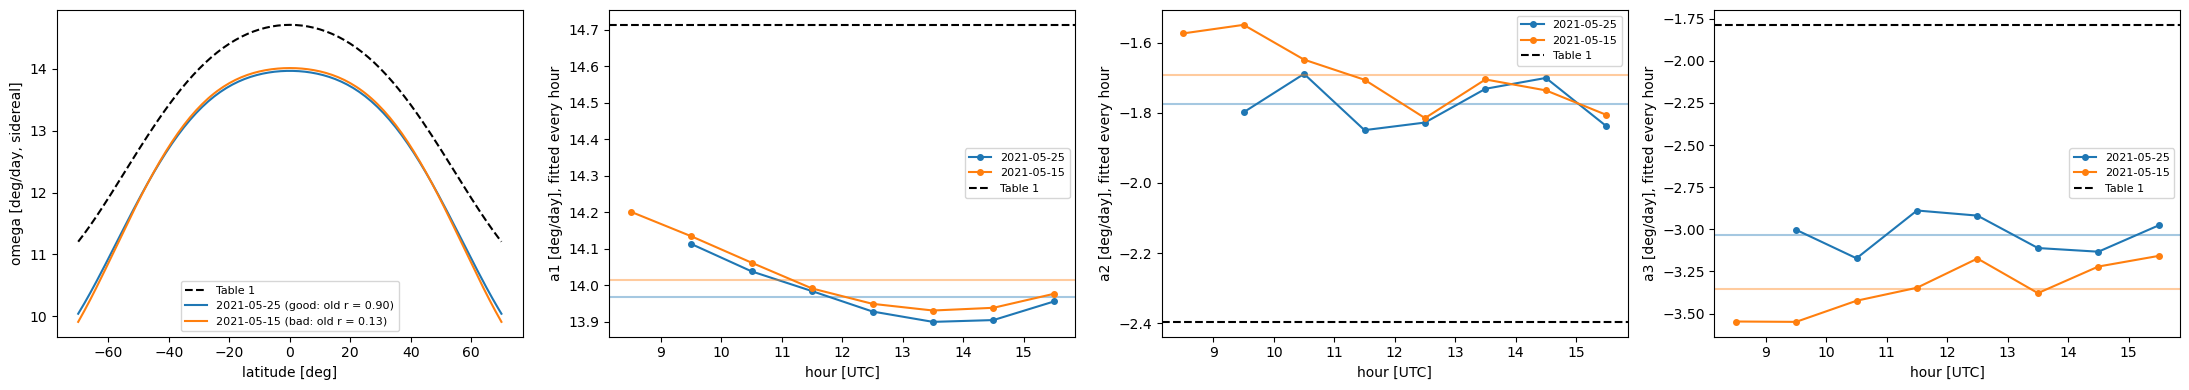

In [4]:
def hourly(d, step=1.0):
    """a1, a2, a3 fitted on the frames of every `step` hours of the day."""
    jd45, swv, sw, swg, _ = frames[d]
    h = (jd45 + 0.5) % 1 * 24
    out = []

    for h0 in np.arange(np.floor(h.min()), h.max(), step):
        k = (h >= h0) & (h < h0 + step)
        if k.sum() >= 20:
            out.append((h0 + step / 2, *sg.fit_rotation(swv[k], sw[k], swg[k], N_RINGS)[0]))
    return np.array(out)

phi = np.linspace(-70, 70, 141)
s2 = np.sin(np.deg2rad(phi)) ** 2
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
axes[0].plot(phi, T1[0] + T1[1] * s2 + T1[2] * s2 ** 2, 'k--', label='Table 1')
for d, r in rot.items():
    axes[0].plot(phi, r[0][0] + r[0][1] * s2 + r[0][2] * s2 ** 2, label='%s (%s)' % (d, DAYS[d]))
    hh = hourly(d)
    for k in range(3):
        axes[k + 1].plot(hh[:, 0], hh[:, k + 1], 'o-', ms=4, label=d)
        axes[k + 1].axhline(r[0][k], color=axes[k + 1].lines[-1].get_color(), alpha=0.4)
for k in range(3):
    axes[k + 1].axhline(T1[k], color='k', ls='--', label='Table 1')
    axes[k + 1].set_xlabel('hour [UTC]'); axes[k + 1].set_ylabel('a%d [deg/day], fitted every hour' % (k + 1))
axes[0].set_xlabel('latitude [deg]'); axes[0].set_ylabel('omega [deg/day, sidereal]')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()

## 3. One dopplergram of each day

In [5]:
def block_mean(a, step):
    """Mean of every block of step x step pixels (NaN ignored)."""
    n = a.shape[0] // step * step
    with np.errstate(invalid='ignore'):
        return np.nanmean(a[:n, :n].reshape(n // step, step, n // step, step), axis=(1, 3))


def one_frame(day, alphas, hour=12.0, step=8):
    """The epoch and the 45 s dopplergram closest to day + hour (UTC): corrections with the rotation of the day and
    of Table 1, identification; the FITS are deleted. Returns images of step x step blocks in the frame of the maps
    (origin='lower')."""
    jd = obs.jd_of_date(day) + hour / 24
    ci = sg.query_records(sg.SERIES['continuum'][0], jd - 600 / 86400, jd + 600 / 86400)
    ci = ci.iloc[[sg.closest(jd, ci['jd'].values)[0][0]]]
    ma = sg.query_records(sg.SERIES['magnetogram'][0], ci['jd'].values[0] - 60 / 86400, ci['jd'].values[0] + 60 / 86400)
    r45 = sg.query_records(sg.SERIES_45S[0], jd - 60 / 86400, jd + 60 / 86400)
    folder = tempfile.mkdtemp(prefix='hmi_')
    try:
        files = sg.fetch_epoch({'continuum': ci['T_REC'].values[0],
                                'magnetogram': ma['T_REC'].values[sg.closest(ci['jd'].values[0], ma['jd'].values)[0][0]]}, folder)
        f45 = sg.fetch_record(sg.SERIES_45S[0], r45['T_REC'].values[sg.closest(jd, r45['jd'].values)[0][0]],
                              sg.SERIES_45S[1], folder)
        ident = sg.identify_epoch(files, size=4096, n_rings=N_RINGS, thresholds=THRESHOLDS)
        ctx = ident['context']
        dop = sg.read_record(*f45)
        c = sg.correct_dopplergram(dop, components=True, basis=True)
        lo, hi = ctx['lo'], ctx['hi']
        cut = lambda a: block_mean(np.flip(np.asarray(a, dtype=np.float32)[lo:hi, lo:hi]), step)
        g = [cut(gk) for gk in c['g']]
        out = {'raw': cut(dop.data), 'v_sc': cut(c['v_sc']), 'mu': cut(c['mu']), 't_obs': f45[1]['T_OBS'],
               'quiet': block_mean(ctx['quiet'].astype(np.float32), step) > 0.5,
               'keys': {k: c[k] for k in ('obs_vr', 'obs_vw', 'obs_vn', 'B0')},
               'ff_sp_disc': ident['ff_sp_disc'], 'ff_fc_disc': ident['ff_fc_disc']}
        v = cut(c['v'])
        for name, a in (('fit', alphas), ('table1', T1)):
            out['v_rot_' + name] = a[0] * g[0] + a[1] * g[1] + a[2] * g[2]
            out['v_' + name] = v - out['v_rot_' + name]
        del dop, c, ident, ctx
    finally:
        shutil.rmtree(folder, ignore_errors=True)
    return out

one = {day: one_frame(day, rot[day][0]) for day in DAYS}
for day, o in one.items():
    print('%s %s: T_OBS %s, OBS_VR %.0f, OBS_VW %.0f, OBS_VN %.0f m/s, B0 %.2f deg, spots %.3f %%, faculae %.2f %%'
          % (day, DAYS[day], o['t_obs'], o['keys']['obs_vr'], o['keys']['obs_vw'], o['keys']['obs_vn'],
             o['keys']['B0'], o['ff_sp_disc'], o['ff_fc_disc']))

/Users/sophiestucki/miniforge3/envs/sunsim/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_32748/1853528788.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(a[:n, :n].reshape(n // step, step, n // step, step), axis=(1, 3))
/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_32748/1853528788.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(a[:n, :n].reshape(n // step, step, n // step, step), axis=(1, 3))


2021-05-25 good: old r = 0.90: T_OBS 2021.05.25_12:00:51_TAI, OBS_VR -1701, OBS_VW 30187, OBS_VN 1555 m/s, B0 -1.44 deg, spots 0.043 %, faculae 1.44 %
2021-05-15 bad: old r = 0.13: T_OBS 2021.05.15_12:00:51_TAI, OBS_VR -1637, OBS_VW 30434, OBS_VN 1462 m/s, B0 -2.61 deg, spots 0.016 %, faculae 1.25 %


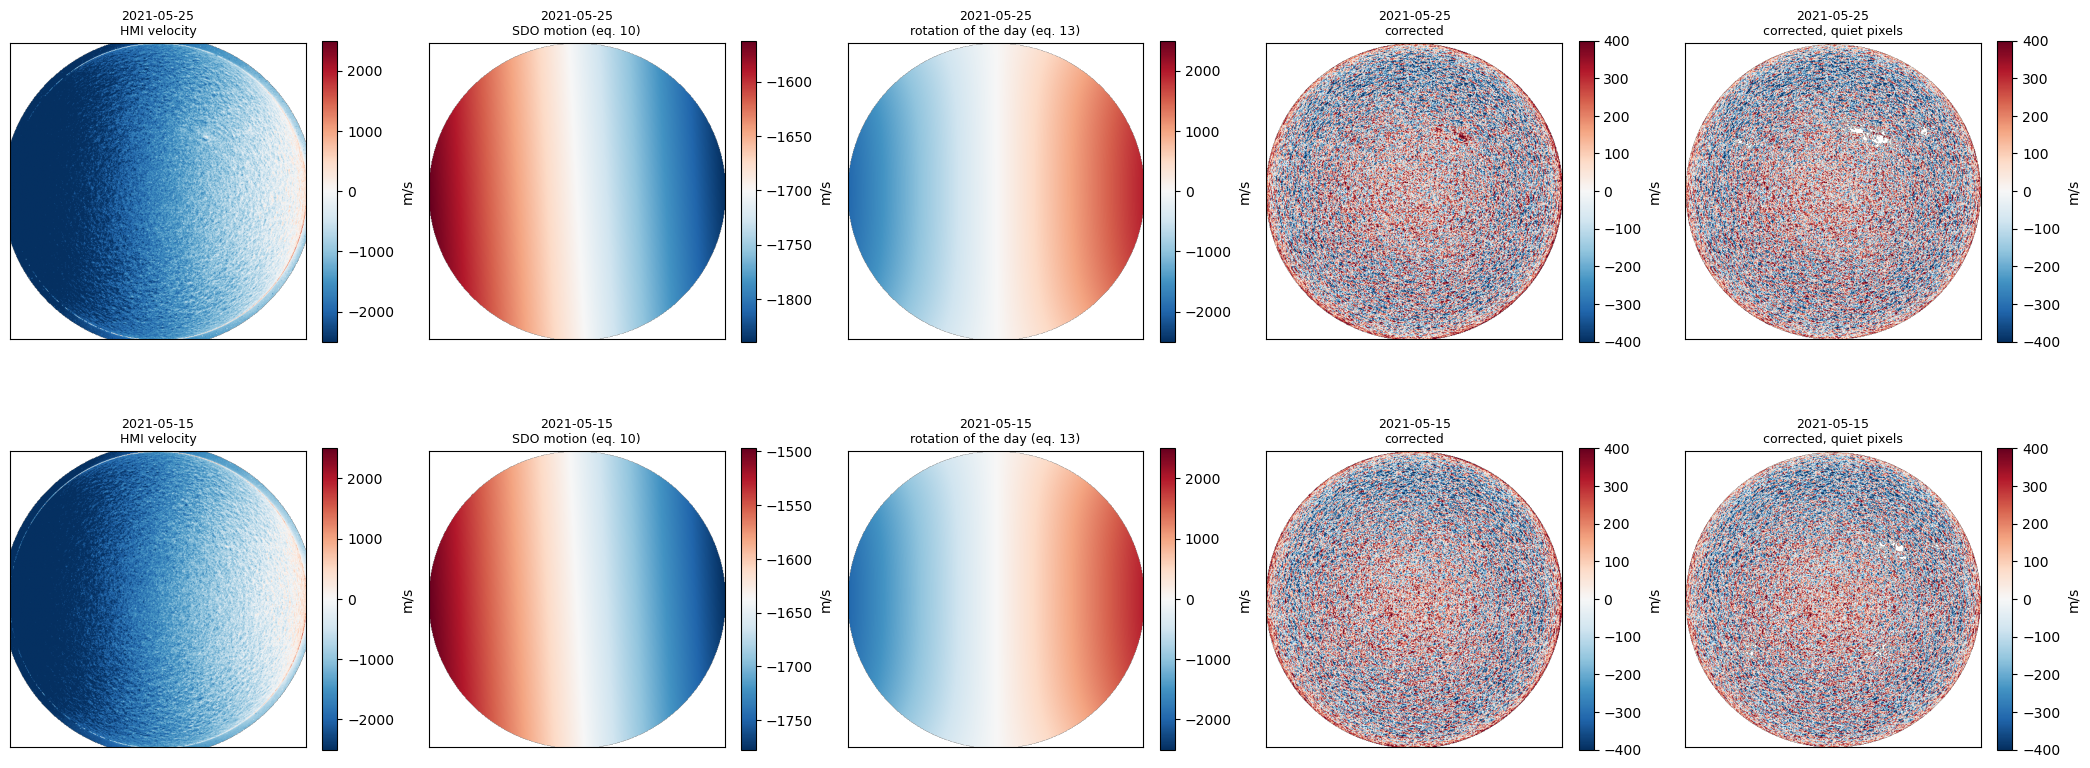

In [6]:
panels = (('raw', 'HMI velocity', 2500), ('v_sc', 'SDO motion (eq. 10)', None),
          ('v_rot_fit', 'rotation of the day (eq. 13)', 2500), ('v_fit', 'corrected', 400),
          ('v_quiet', 'corrected, quiet pixels', 400))
fig, axes = plt.subplots(len(one), len(panels), figsize=(4.2 * len(panels), 4.2 * len(one)), squeeze=False)
for row, (day, o) in zip(axes, one.items()):
    o['v_quiet'] = np.where(o['quiet'] & (o['mu'] > MU_MIN), o['v_fit'], np.nan)
    for ax, (key, title, lim) in zip(row, panels):
        a = o[key]
        vmin, vmax = (np.nanmin(a), np.nanmax(a)) if lim is None else (-lim, lim)
        im = ax.imshow(a, origin='lower', cmap='RdBu_r', vmin=vmin, vmax=vmax)
        ax.set_title('%s\n%s' % (day, title), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046, label='m/s')
plt.tight_layout()

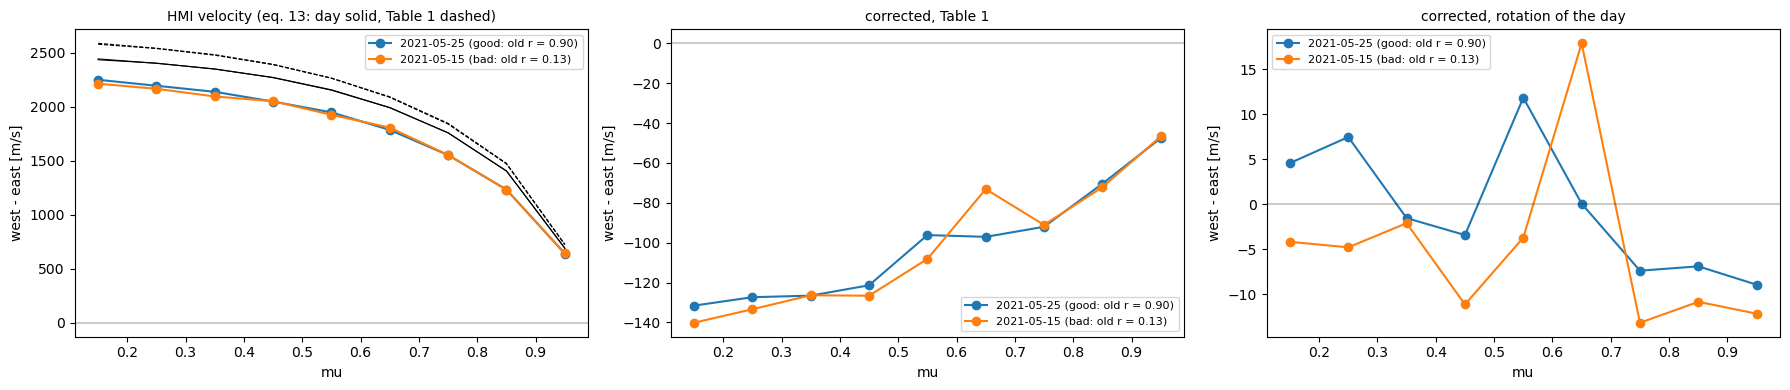

In [7]:
def west_east(a, mu, bins=np.linspace(0.1, 1, 10)):
    """Median of a in the west half minus in the east half, in bins of mu (frame of the maps: west on the right)."""
    x = np.arange(a.shape[1])[None, :] - (a.shape[1] - 1) / 2 + np.zeros(a.shape)
    out = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        k = np.isfinite(a) & (mu >= lo) & (mu < hi)
        out.append(np.nanmedian(a[k & (x > 0)]) - np.nanmedian(a[k & (x < 0)]))
    return (bins[:-1] + bins[1:]) / 2, np.array(out)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for day, o in one.items():
    for ax, key in zip(axes, ('raw', 'v_table1', 'v_fit')):
        mu_c, d = west_east(o[key], o['mu'])
        ax.plot(mu_c, d, 'o-', label='%s (%s)' % (day, DAYS[day]))
    for key, ls in (('v_rot_fit', '-'), ('v_rot_table1', '--')):
        mu_c, d = west_east(o[key], o['mu'])
        axes[0].plot(mu_c, d, 'k' + ls, lw=0.8)
for ax, t in zip(axes, ('HMI velocity (eq. 13: day solid, Table 1 dashed)', 'corrected, Table 1', 'corrected, rotation of the day')):
    ax.axhline(0, color='k', alpha=0.2)
    ax.set_xlabel('mu'); ax.set_ylabel('west - east [m/s]'); ax.set_title(t, fontsize=10); ax.legend(fontsize=8)
plt.tight_layout()

## 4. Velocities of the cells of every exposure

In [8]:
v_exp = np.full((len(ex['jd']), ep['ff_sp'].shape[1]), np.nan)
sw_exp = np.zeros_like(v_exp)
n45, ok45 = np.zeros(len(ex['jd']), int), np.zeros(len(ex['jd']), bool)
for d in DAYS:
    m = np.flatnonzero(ex['day'] == d)
    jd45, swv, sw, swg, info = frames[d]
    v_exp[m], sw_exp[m], n45[m], ok45[m] = sg.window_average(jd45, sg.remove_rotation(swv, swg, rot[d][0]), sw,
                                                             ex['jd'][m], window=WINDOW)
v_fill, filled = sg.fill_empty_cells(v_exp, sw_exp, N_RINGS)
fr = pd.concat([pd.DataFrame(frames[d][4]).assign(day=d) for d in DAYS], ignore_index=True)
print('exposures: %s; frames per exposure %d to %d; with >= 80 %% of the frames: %d of %d; empty cells per exposure %.1f'
      % (dict(zip(*np.unique(ex['day'], return_counts=True))), n45.min(), n45.max(), ok45.sum(), len(ok45),
         filled.sum(axis=1).mean()))

exposures: {np.str_('2021-05-15'): np.int64(71), np.str_('2021-05-25'): np.int64(71)}; frames per exposure 8 to 16; with >= 80 % of the frames: 139 of 142; empty cells per exposure 134.3


/Users/sophiestucki/sunsim/sunsim/sdo.py:402: UserWarning: 2 cells of the grid of 30 rings have no pixel in 512 x 512 maps (taken as quiet): use larger maps or fewer rings (max_rings)
  warnings.warn('%d cells of the grid of %d rings have no pixel in %d x %d maps (taken as quiet): use larger '


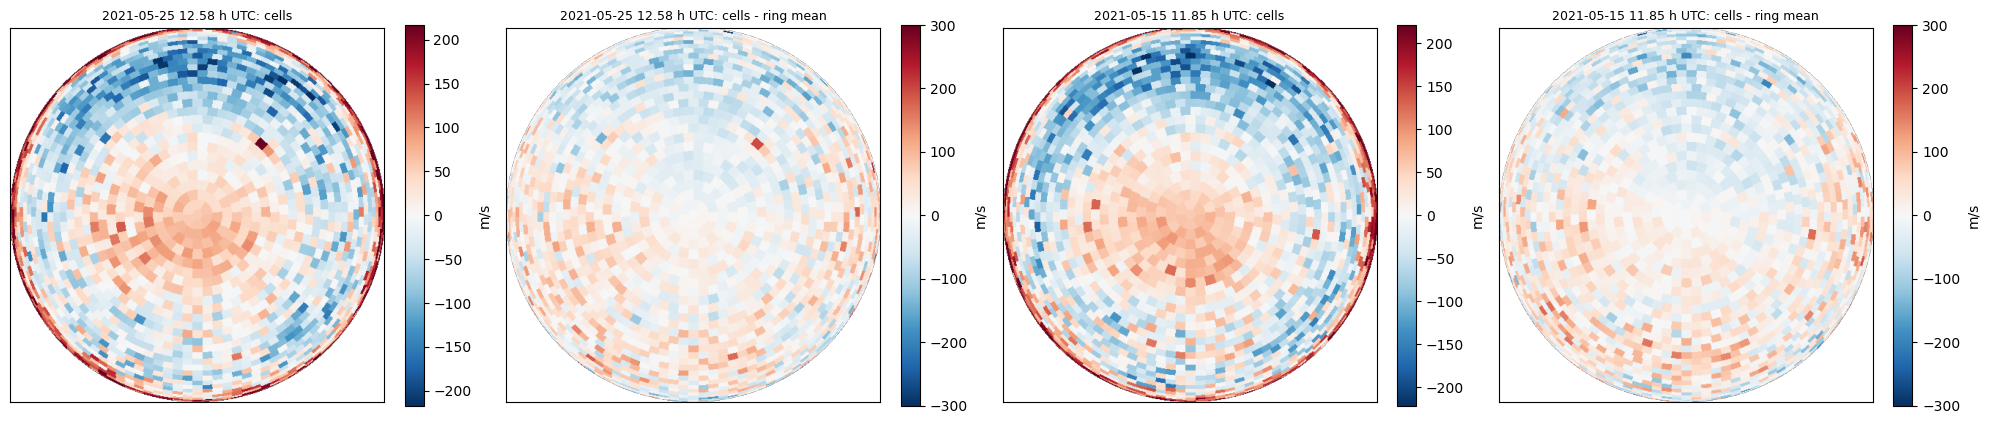

In [9]:
SIZE = 512
cells, npix = sdo.cell_projection((SIZE, SIZE), N_RINGS)
x_pix = (np.tile(np.arange(SIZE), SIZE) + 0.5) / SIZE * 2 - 1                # west > 0, solar radii
x_cell = np.bincount(cells[cells >= 0], weights=x_pix[cells >= 0], minlength=len(npix)) / np.maximum(npix, 1)
ring = sg.ring_of_cells(N_RINGS)

def cell_image(v):
    img = np.full(SIZE * SIZE, np.nan)
    img[cells >= 0] = v[cells[cells >= 0]]
    return img.reshape(SIZE, SIZE)

def rotation_left(v, w):
    """Fit of v = A x + one mean per ring over the cells (weights w): A [m/s at the limb]."""
    k = np.isfinite(v) & (w > 0)
    X = np.column_stack([x_cell[k]] + [(ring[k] == i).astype(float) for i in range(N_RINGS)])
    sq = np.sqrt(w[k])
    return np.linalg.lstsq(X * sq[:, None], v[k] * sq, rcond=None)[0][0]

ex['rot_left'] = np.array([rotation_left(v_exp[i], sw_exp[i]) for i in range(len(ex['jd']))])
fig, axes = plt.subplots(1, 2 * len(DAYS), figsize=(5 * 2 * len(DAYS), 4.4))
for k, d in enumerate(DAYS):
    i = np.flatnonzero(ex['day'] == d)[np.sum(ex['day'] == d) // 2]
    mean_ring = np.array([np.nansum(v_fill[i][ring == r] * sw_exp[i][ring == r]) / np.sum(sw_exp[i][ring == r]) for r in range(N_RINGS)])
    for ax, img, t, lim in ((axes[2 * k], cell_image(v_fill[i]), 'cells', None),
                            (axes[2 * k + 1], cell_image(v_fill[i] - mean_ring[ring]), 'cells - ring mean', 300)):
        lim = lim or np.nanpercentile(np.abs(img), 99)
        im = ax.imshow(img, origin='lower', cmap='RdBu_r', vmin=-lim, vmax=lim)
        ax.set_title('%s %.2f h UTC: %s' % (d, (ex['jd'][i] + 0.5) % 1 * 24, t), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046, label='m/s')
plt.tight_layout()

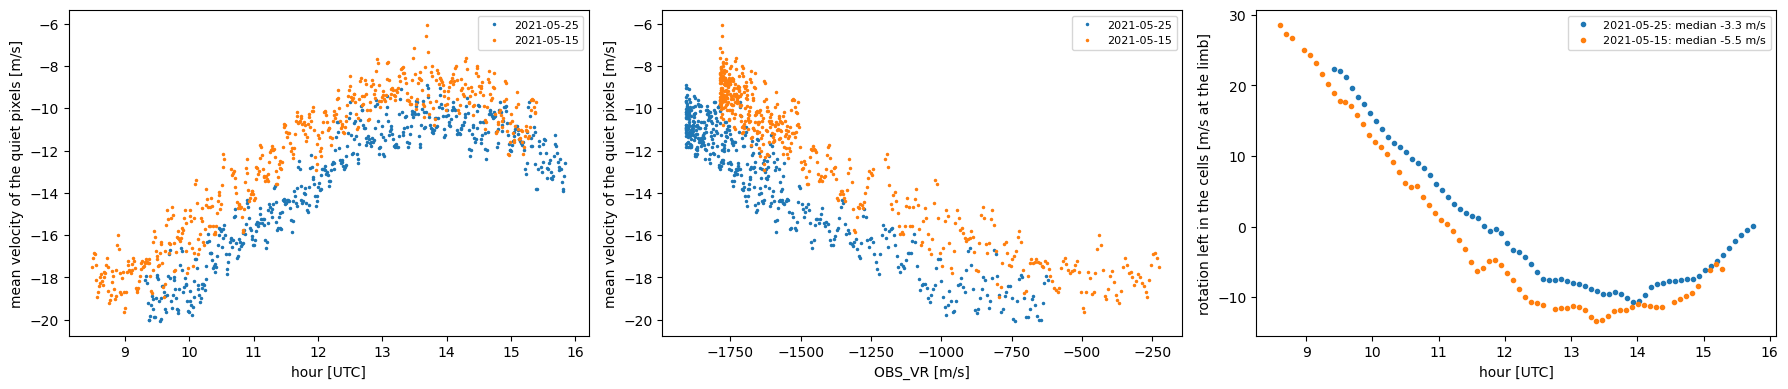

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for d in DAYS:
    f = fr[fr['day'] == d]
    axes[0].plot((f['jd'] + 0.5) % 1 * 24, f['v_quiet_mean'], '.', ms=3, label=d)
    axes[1].plot(f['obs_vr'], f['v_quiet_mean'], '.', ms=3, label=d)
    m = ex['day'] == d
    axes[2].plot((ex['jd'][m] + 0.5) % 1 * 24, ex['rot_left'][m], 'o', ms=3, label='%s: median %.1f m/s' % (d, np.median(ex['rot_left'][m])))
axes[0].set_xlabel('hour [UTC]'); axes[0].set_ylabel('mean velocity of the quiet pixels [m/s]')
axes[1].set_xlabel('OBS_VR [m/s]'); axes[1].set_ylabel('mean velocity of the quiet pixels [m/s]')
axes[2].set_xlabel('hour [UTC]'); axes[2].set_ylabel('rotation left in the cells [m/s at the limb]')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()

## 5. Simulations and comparison with HARPS-N

In [11]:
a = Namespace(out=OUT, start=START, conf=os.path.join('..', 'conf', 'starsim_sun_sdo_mps_highres.conf'),
              mps_folder=str(local_path('muram_spectra')), mask=str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'),
              interventions=str(local_path('harpsn_interventions')), n_rings=N_RINGS, window=WINDOW, min_fill=0.8,
              min_exp=5, harpsn=HARPSN, min_obs_quality=MIN_OBS_QUALITY, min_day_exp=MIN_DAY_EXP, results=RESULTS,
              figures=True, diff_extinction=DIFF_EXTINCTION)
sgh.run_collect(a)
for folder, opt, _ in VARIANTS.values():
    sgh.run_collect(Namespace(**dict(vars(a), results=folder, **opt)))

16:42:37 quality: 410 of 2523 exposures left out (data_quality != 1: 0, not in the release: 0, obs_quality < 0.99: 410)
16:42:37 days with fewer than 50 exposures left: 11 (362 exposures)
16:42:40 rotation of the days [deg/day]: a1 13.882 to 14.155, a2 -2.05 to -1.43, a3 -3.65 to -2.56 (Table 1: (14.713, -2.396, -1.787))
16:42:40 dopplergrams: 20270 frames, window 720 s: 1737 of 1751 exposures with >= 80 % of the frames (left out: 14)
16:42:41 cells without quiet pixels (ring mean): 137.2 per exposure
16:42:41 1737 exposures on 26 days, 1227 epochs
16:42:41 differential extinction removed from the HARPS-N RV: -1.45 to 0.83 m/s
16:42:42 2 simulations of 1737 exposures: 1 s
   quantity               model  days  exposures  median r  days with r > 0 [%]  median slope  RMS obs (intra-day)  RMS obs - sim (intra-day)
0        rv                maps    26       1737     0.143               65.385         7.495                0.548                      0.546
1        rv  maps + dopplergram    

In [12]:
key = lambda df: np.round(df['jd_utc'] * 86400).astype(np.int64)
new = pd.read_csv(os.path.join(OUT, RESULTS, 'exposures.csv'))
new = new[new['day'].isin(list(DAYS))]
both = new.assign(k=key(new))
SERIES = [('%s_maps', 'maps', COL['maps'], ''), ('%s_maps_dopplergram', 'maps + dopplergram (rotation of the day)', COL['new'], '')]
for j, (label, (folder, _, colour)) in enumerate(VARIANTS.items()):
    v = pd.read_csv(os.path.join(OUT, folder, 'exposures.csv'))
    both = both.merge(v.add_suffix('_v%d' % j).assign(k=key(v))[['k'] + [c + '_v%d' % j for c in v.columns if 'dopplergram' in c]], on='k')
    SERIES.append(('%s_maps_dopplergram', 'maps + dopplergram (%s)' % label, colour, '_v%d' % j))
t1_file = os.path.join(OUT, TABLE1_RESULTS, 'exposures.csv')
if os.path.exists(t1_file):
    t1 = pd.read_csv(t1_file)
    both = both.merge(t1.add_suffix('_t1').assign(k=key(t1))[['k'] + [c + '_t1' for c in t1.columns if 'dopplergram' in c]], on='k')
    SERIES.append(('%s_maps_dopplergram', 'maps + dopplergram (Table 1)', COL['table1'], '_t1'))
print('exposures: new %d, in all the runs %d' % (len(new), len(both)))
LABEL = {'rv': ('RV', 'm/s'), 'fwhm': ('FWHM', 'm/s'), 'bis': ('BIS', 'm/s'), 'contrast': ('contrast', 'ppm')}

def intra(df, col):
    return df[col] - df.groupby('day')[col].transform('median')

rows = []
for q in LABEL:
    for d in DAYS:
        b = both[both['day'] == d]
        for obs_col, obs_name in (('%s_obs' % q, 'rv_raw - JPL'),) + ((('rv_release', 'release'),) if q == 'rv' else ()):
            o = intra(b, obs_col)
            for col, name, _, suf in SERIES:
                s = intra(b, (col % q) + suf)
                rows.append({'quantity': q, 'day': d, 'HARPS-N': obs_name, 'model': name, 'n': len(b),
                             'RMS obs': np.std(o), 'RMS obs - sim': np.std(o - s), 'r': np.corrcoef(o, s)[0, 1]})
stats = pd.DataFrame(rows)
stats.pivot_table(index=['quantity', 'day', 'HARPS-N'], columns='model', values=['RMS obs - sim', 'r'], sort=False).round(2)

exposures: new 132, in all the runs 132


RMS obs - sim  \
model                                     maps   
quantity day        HARPS-N                      
rv       2021-05-25 rv_raw - JPL          0.79   
                    release               0.79   
         2021-05-15 rv_raw - JPL          0.35   
                    release               0.35   
fwhm     2021-05-25 rv_raw - JPL          1.35   
         2021-05-15 rv_raw - JPL          1.16   
bis      2021-05-25 rv_raw - JPL          0.62   
         2021-05-15 rv_raw - JPL          0.60   
contrast 2021-05-25 rv_raw - JPL        140.10   
         2021-05-15 rv_raw - JPL        132.10   

                                                                           \
model                            maps + dopplergram (rotation of the day)   
quantity day        HARPS-N                                                 
rv       2021-05-25 rv_raw - JPL                                     2.73   
                    release                                          2.73   
         2021-05-15 rv_raw - JPL                                     3.63   
                    release                                          3.63   
fwhm     2021-05-25 rv_raw - JPL                                     3.75   
         2021-05-15 rv_raw - JPL                                     5.11   
bis      2021-05-25 rv_raw - JPL                                     0.83   
         2021-05-15 rv_raw - JPL                                     0.89   
contrast 2021-05-25 rv_raw - JPL                                   585.58   
         2021-05-15 rv_raw - JPL                                   837.40   

                                                                         \
model                            maps + dopplergram (disc mean removed)   
quantity day        HARPS-N                                               
rv       2021-05-25 rv_raw - JPL                                   0.88   
                    release                                        0.88   
         2021-05-15 rv_raw - JPL                                   0.38   
                    release                                        0.38   
fwhm     2021-05-25 rv_raw - JPL                                   3.66   
         2021-05-15 rv_raw - JPL                                   5.00   
bis      2021-05-25 rv_raw - JPL                                   0.83   
         2021-05-15 rv_raw - JPL                                   0.89   
contrast 2021-05-25 rv_raw - JPL                                 591.18   
         2021-05-15 rv_raw - JPL                                 843.89   

                                                                      \
model                            maps + dopplergram (a1 + a4 OBS_VR)   
quantity day        HARPS-N                                            
rv       2021-05-25 rv_raw - JPL                                2.64   
                    release                                     2.64   
         2021-05-15 rv_raw - JPL                                3.51   
                    release                                     3.51   
fwhm     2021-05-25 rv_raw - JPL                                1.21   
         2021-05-15 rv_raw - JPL                                1.09   
bis      2021-05-25 rv_raw - JPL                                0.95   
         2021-05-15 rv_raw - JPL                                1.07   
contrast 2021-05-25 rv_raw - JPL                              111.22   
         2021-05-15 rv_raw - JPL                              108.89   

                                                                                             \
model                            maps + dopplergram (a1 + a4 OBS_VR, CLV(OBS_VR) - average)   
quantity day        HARPS-N                                                                   
rv       2021-05-25 rv_raw - JPL                                               0.33           
                    release                                                    0.33    

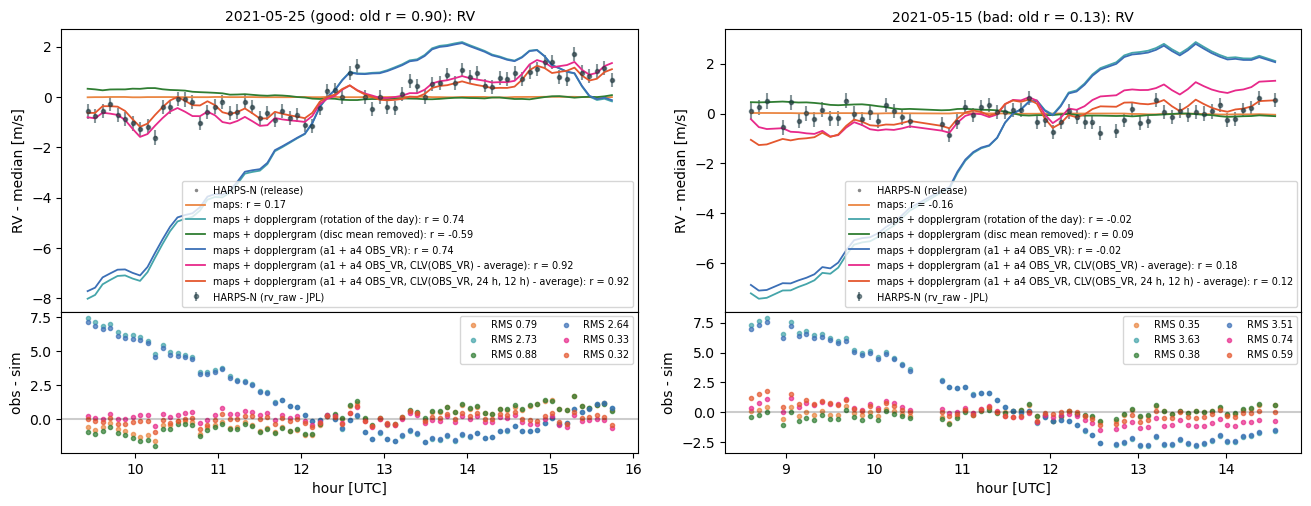

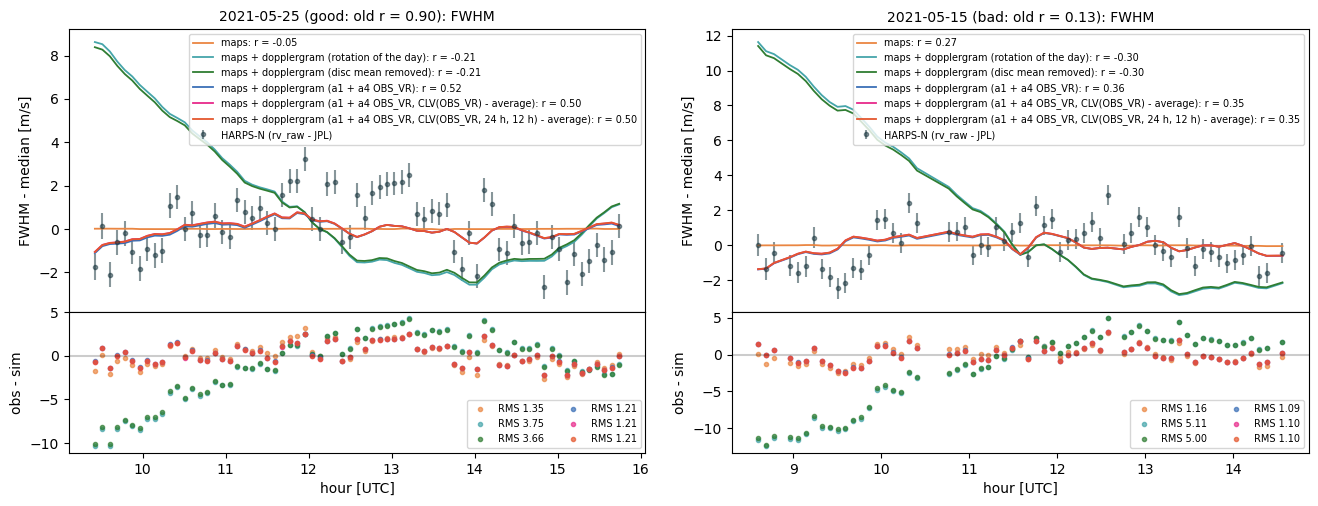

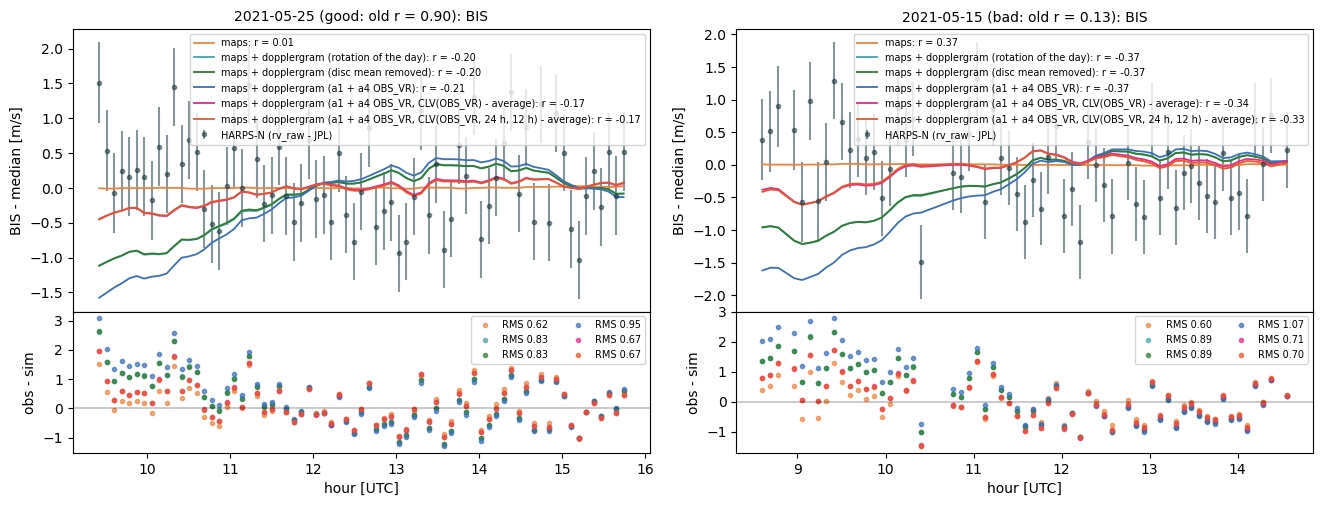

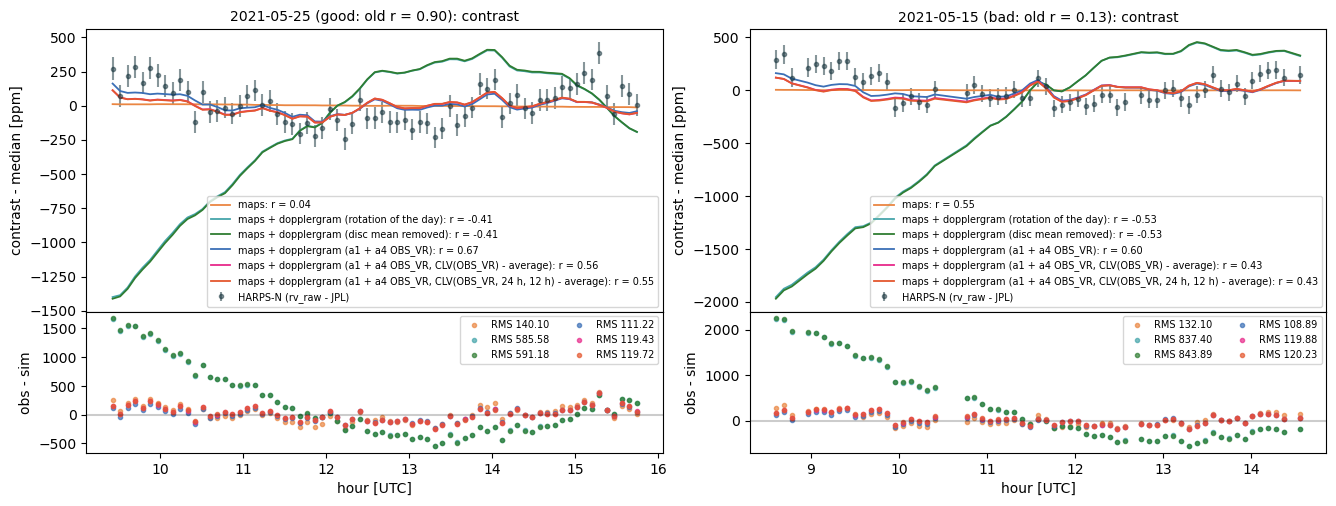

In [13]:
for q, (label, unit) in LABEL.items():
    fig = plt.figure(figsize=(8 * len(DAYS), 5.5))
    outer = fig.add_gridspec(1, len(DAYS), wspace=0.15)
    for k, d in enumerate(DAYS):
        inner = outer[k].subgridspec(2, 1, height_ratios=[2, 1], hspace=0)
        ax, ar = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
        b = both[both['day'] == d]
        h = (b['jd_utc'] + 0.5) % 1 * 24
        o = intra(b, '%s_obs' % q)
        ax.errorbar(h, o, yerr=b['%s_err' % q], fmt='o', ms=3, color=COL['harpsn'], alpha=0.5, label='HARPS-N (rv_raw - JPL)')
        if q == 'rv':
            ax.plot(h, intra(b, 'rv_release'), '.', ms=3, color='#888888', label='HARPS-N (release)')
        for col, name, c, suf in SERIES:
            s = intra(b, (col % q) + suf)
            ax.plot(h, s, '-', color=c, lw=1.3, label='%s: r = %.2f' % (name, np.corrcoef(o, s)[0, 1]))
            ar.plot(h, o - s, 'o', ms=3, color=c, alpha=0.7, label='RMS %.2f' % np.std(o - s))
        ar.axhline(0, color='k', alpha=0.2)
        ax.tick_params(labelbottom=False)
        ax.set_title('%s (%s): %s' % (d, DAYS[d], label), fontsize=10)
        ax.set_ylabel('%s - median [%s]' % (label, unit)); ar.set_ylabel('obs - sim'); ar.set_xlabel('hour [UTC]')
        ax.legend(fontsize=7); ar.legend(fontsize=7, ncols=2)
    plt.show()

## 6. HARPS-N in the rest frame of the Sun

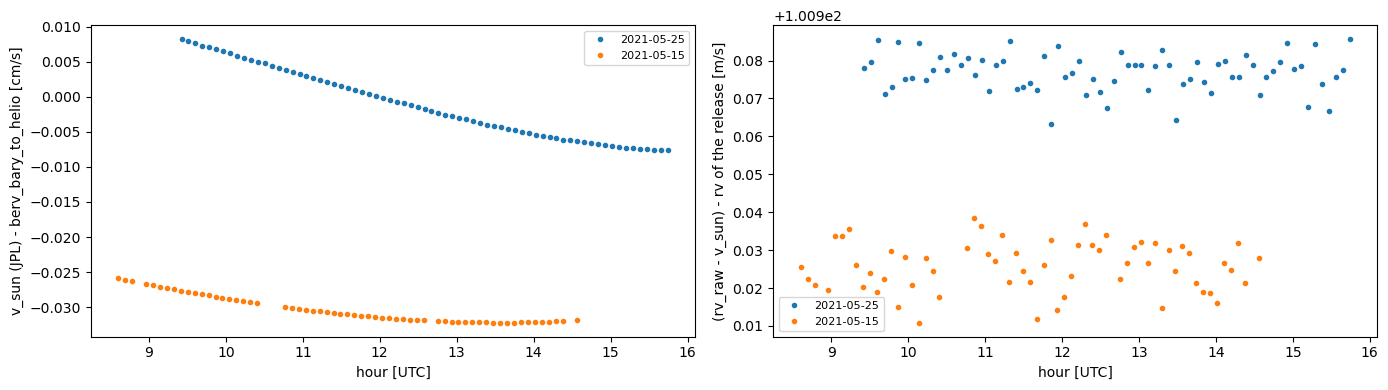

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for d in DAYS:
    b = new[new['day'] == d]
    h = (b['jd_utc'] + 0.5) % 1 * 24
    axes[0].plot(h, 100 * (b['v_sun_jpl'] - b['berv_bary_to_helio']), '.', label=d)
    axes[1].plot(h, b['rv_obs'] - b['rv_release'], '.', label=d)
axes[0].set_ylabel('v_sun (JPL) - berv_bary_to_helio [cm/s]')
axes[1].set_ylabel('(rv_raw - v_sun) - rv of the release [m/s]')
for ax in axes:
    ax.set_xlabel('hour [UTC]'); ax.legend(fontsize=8)
plt.tight_layout()

## 7. RV: maps + dopplergram (CLV with OBS_VR, 24 h and 12 h) against HARPS-N, linear correlation

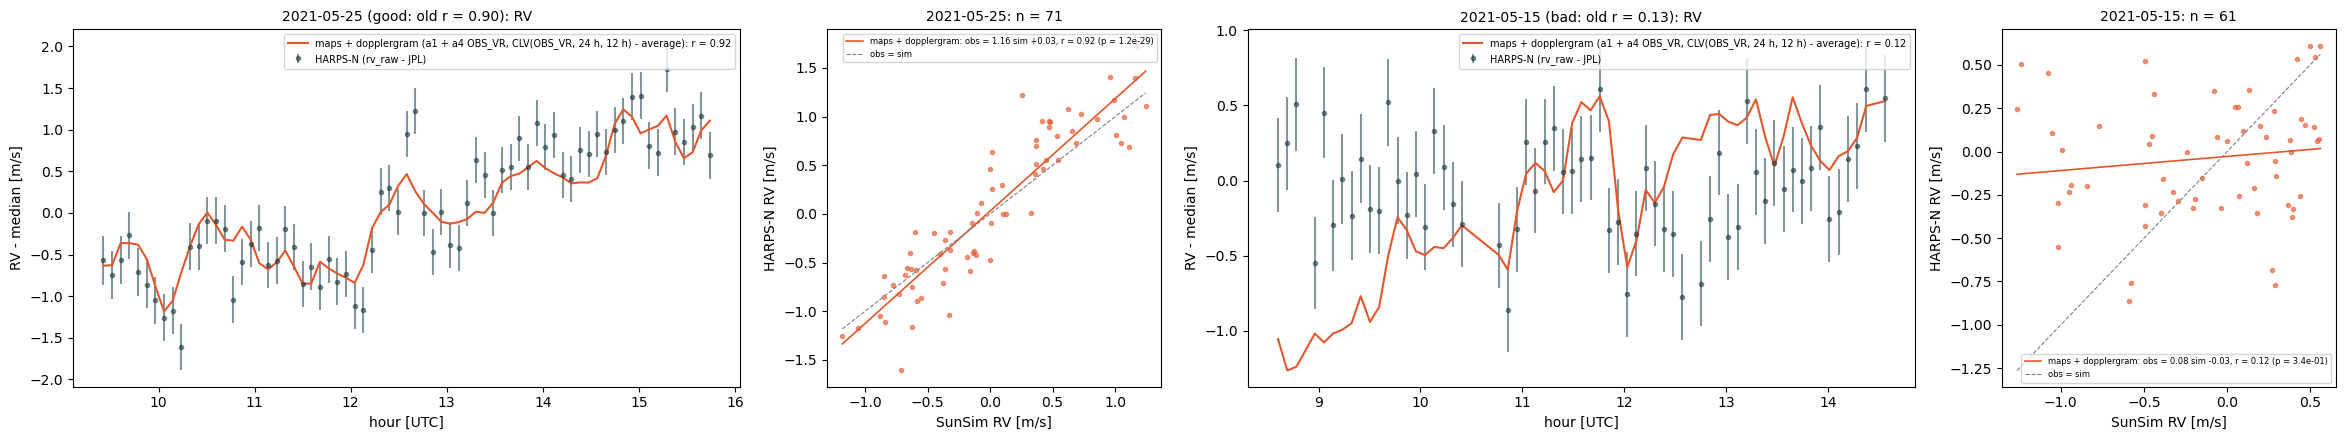

,day,label,model,n,r,p,slope,intercept,rms_obs,rms_sim,rms_obs_minus_sim,rms_obs_minus_fit
0,2021-05-25,good: old r = 0.90,"maps + dopplergram (a1 + a4 OBS_VR, CLV(OBS_VR...",71,0.919,0.000,1.155,0.029,0.787,0.626,0.325,0.310
1,2021-05-15,bad: old r = 0.13,"maps + dopplergram (a1 + a4 OBS_VR, CLV(OBS_VR...",61,0.125,0.337,0.081,-0.029,0.344,0.529,0.594,0.341


In [15]:
from scipy.stats import pearsonr

PINK = 'a1 + a4 OBS_VR, CLV(OBS_VR) - average'
H2 = 'a1 + a4 OBS_VR, CLV(OBS_VR, 24 h, 12 h) - average'
MODELS = [('rv_maps_dopplergram_v%d' % list(VARIANTS).index(H2), 'maps + dopplergram (%s)' % H2, VARIANTS[H2][2])]
fig, axes = plt.subplots(1, 2 * len(DAYS), figsize=(6 * 2 * len(DAYS), 4.5),
                         gridspec_kw=dict(width_ratios=[2, 1] * len(DAYS)))
rows = []
for k, d in enumerate(DAYS):
    b = both[both['day'] == d]
    h = (b['jd_utc'] + 0.5) % 1 * 24
    o = intra(b, 'rv_obs')
    ax, sc = axes[2 * k], axes[2 * k + 1]
    ax.errorbar(h, o, yerr=b['rv_err'], fmt='o', ms=3, color=COL['harpsn'], alpha=0.5, label='HARPS-N (rv_raw - JPL)')
    lim = [np.inf, -np.inf]
    for col, name, colour in MODELS:
        s = intra(b, col)
        r, p = pearsonr(s, o)
        slope, icpt = np.polyfit(s, o, 1)
        rows.append(dict(day=d, label=DAYS[d], model=name, n=len(b), r=r, p=p, slope=slope, intercept=icpt,
                         rms_obs=np.std(o), rms_sim=np.std(s), rms_obs_minus_sim=np.std(o - s),
                         rms_obs_minus_fit=np.std(o - (slope * s + icpt))))
        ax.plot(h, s, '-', color=colour, lw=1.5, label='%s: r = %.2f' % (name, r))
        sc.plot(s, o, 'o', ms=3, color=colour, alpha=0.6)
        x = np.linspace(s.min(), s.max(), 2)
        sc.plot(x, slope * x + icpt, '-', color=colour, lw=1.2,
                label='%s: obs = %.2f sim %+.2f, r = %.2f (p = %.1e)' % (name.split(' (')[0], slope, icpt, r, p))
        lim = [min(lim[0], s.min()), max(lim[1], s.max())]
    sc.plot(lim, lim, '--', color='grey', lw=0.8, label='obs = sim')
    ax.set_title('%s (%s): RV' % (d, DAYS[d]), fontsize=10)
    ax.set_xlabel('hour [UTC]'); ax.set_ylabel('RV - median [m/s]')
    ax.legend(fontsize=7)
    sc.set_title('%s: n = %d' % (d, len(b)), fontsize=10)
    sc.set_xlabel('SunSim RV [m/s]'); sc.set_ylabel('HARPS-N RV [m/s]')
    sc.legend(fontsize=6)
plt.tight_layout()
plt.show()
pink = pd.DataFrame(rows)
pink.round(3)

## 8. RV within the day with the linear trend of the day removed (HARPS-N and SunSim): residuals and linear correlation

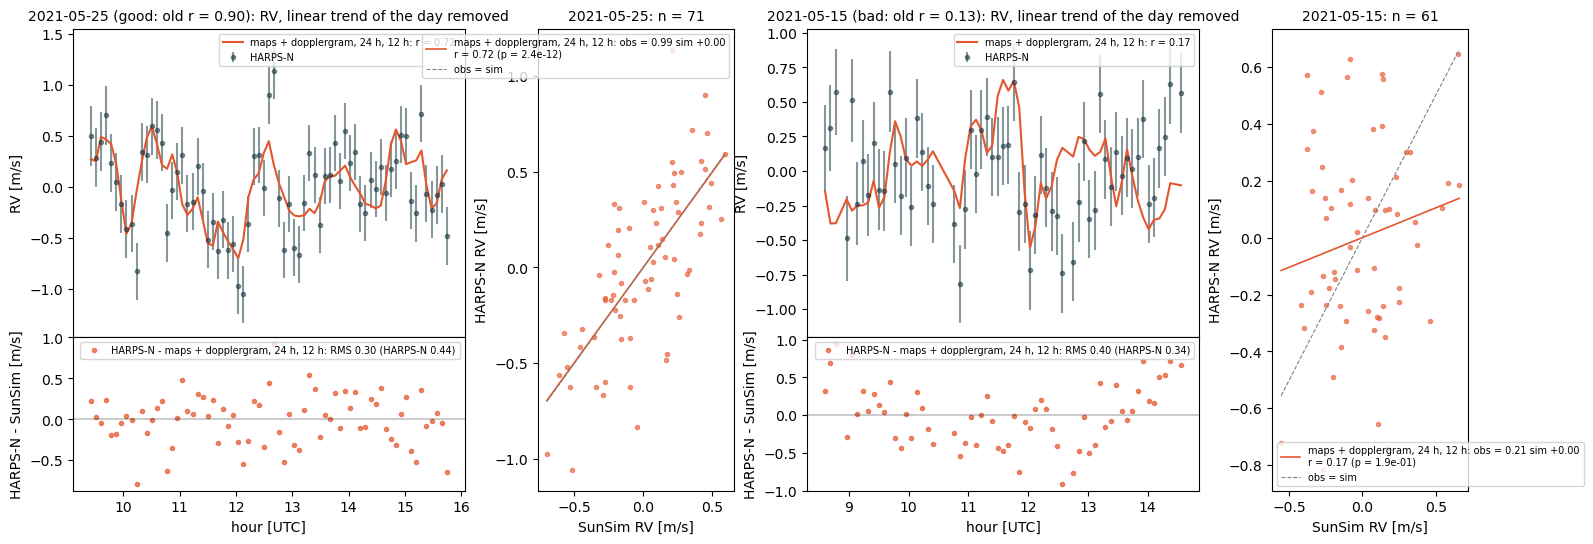

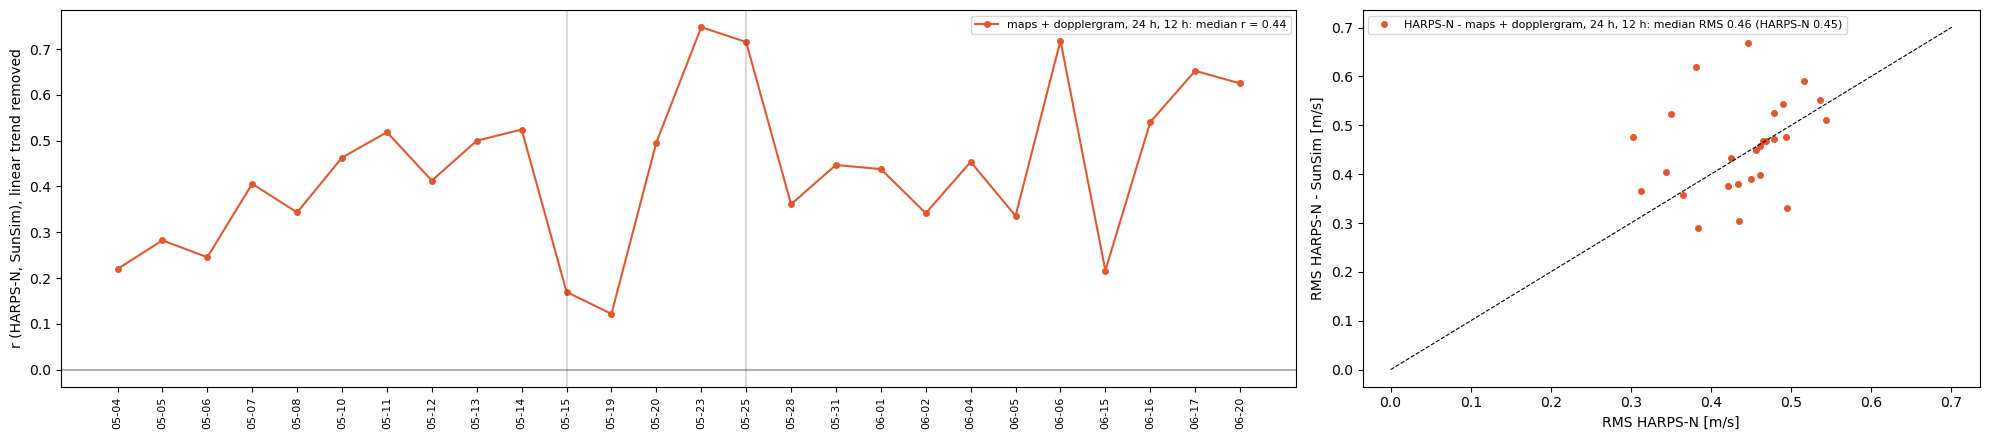

,day,n,rms_obs,"r maps + dopplergram, 24 h, 12 h","p maps + dopplergram, 24 h, 12 h","slope maps + dopplergram, 24 h, 12 h","rms obs - maps + dopplergram, 24 h, 12 h"
0,2021-05-04,60,0.447,0.220,0.092,0.163,0.668
1,2021-05-05,96,0.517,0.282,0.005,0.311,0.592
2,2021-05-06,60,0.350,0.245,0.059,0.178,0.523
3,2021-05-07,60,0.313,0.406,0.001,0.359,0.365
4,2021-05-08,59,0.490,0.343,0.008,0.368,0.543
5,2021-05-10,66,0.494,0.463,0.000,0.551,0.476
6,2021-05-11,69,0.434,0.518,0.000,0.744,0.379
7,2021-05-12,64,0.536,0.413,0.001,0.462,0.552
8,2021-05-13,74,0.478,0.500,0.000,0.515,0.472
9,2021-05-14,65,0.544,0.524,0.000,0.572,0.510


In [16]:
p_all = pd.read_csv(os.path.join(OUT, VARIANTS[PINK][0], 'exposures.csv'))     # all the days of the pink run
h2 = pd.read_csv(os.path.join(OUT, VARIANTS[H2][0], 'exposures.csv'))
p_all = p_all.merge(h2[['jd_utc', 'rv_maps_dopplergram']].rename(columns={'rv_maps_dopplergram': 'rv_h2'}), on='jd_utc')
p_all['h'] = (p_all['jd_utc'] + 0.5) % 1 * 24
MODELS_D = [('rv_h2', 'maps + dopplergram, 24 h, 12 h', VARIANTS[H2][2])]


def detrend(b, col):
    """col of the exposures b minus a straight line in the hour, fitted on the day."""
    return b[col] - np.polyval(np.polyfit(b['h'], b[col], 1), b['h'])


# the two days: RV with the line of the day removed, residuals, correlation
fig = plt.figure(figsize=(9 * len(DAYS), 6))
outer = fig.add_gridspec(1, 2 * len(DAYS), width_ratios=[2, 1] * len(DAYS), wspace=0.25)
for k, d in enumerate(DAYS):
    b = p_all[p_all['day'] == d]
    o = detrend(b, 'rv_obs')
    inner = outer[2 * k].subgridspec(2, 1, height_ratios=[2, 1], hspace=0)
    ax, ar = fig.add_subplot(inner[0]), fig.add_subplot(inner[1], sharex=None)
    sc = fig.add_subplot(outer[2 * k + 1])
    ax.errorbar(b['h'], o, yerr=b['rv_err'], fmt='o', ms=3, color=COL['harpsn'], alpha=0.5, label='HARPS-N')
    lim = [np.inf, -np.inf]
    for col, name, colour in MODELS_D:
        s = detrend(b, col)
        r, p = pearsonr(s, o)
        slope, icpt = np.polyfit(s, o, 1)
        ax.plot(b['h'], s, '-', color=colour, lw=1.5, label='%s: r = %.2f' % (name, r))
        ar.plot(b['h'], o - s, 'o', ms=3, color=colour, alpha=0.7,
                label='HARPS-N - %s: RMS %.2f (HARPS-N %.2f)' % (name, np.std(o - s), np.std(o)))
        sc.plot(s, o, 'o', ms=3, color=colour, alpha=0.6)
        x = np.linspace(s.min(), s.max(), 2)
        sc.plot(x, slope * x + icpt, '-', color=colour, lw=1.2,
                label='%s: obs = %.2f sim %+.2f\nr = %.2f (p = %.1e)' % (name, slope, icpt, r, p))
        lim = [min(lim[0], s.min()), max(lim[1], s.max())]
    sc.plot(lim, lim, '--', color='grey', lw=0.8, label='obs = sim')
    ar.axhline(0, color='k', alpha=0.2)
    ax.tick_params(labelbottom=False)
    ax.set_title('%s (%s): RV, linear trend of the day removed' % (d, DAYS[d]), fontsize=10)
    ax.set_ylabel('RV [m/s]'); ar.set_ylabel('HARPS-N - SunSim [m/s]'); ar.set_xlabel('hour [UTC]')
    ax.legend(fontsize=7); ar.legend(fontsize=7)
    sc.set_title('%s: n = %d' % (d, len(b)), fontsize=10)
    sc.set_xlabel('SunSim RV [m/s]'); sc.set_ylabel('HARPS-N RV [m/s]')
    sc.legend(fontsize=7)
plt.show()

# all the days of the run, linear trend of the day removed
rows = []
for d, b in p_all.groupby('day'):
    if len(b) < 20:
        continue
    o = detrend(b, 'rv_obs')
    row = dict(day=d, n=len(b), rms_obs=np.std(o))
    for col, name, _ in MODELS_D:
        s = detrend(b, col)
        row['r ' + name], row['p ' + name] = pearsonr(s, o)
        row['slope ' + name] = np.polyfit(s, o, 1)[0]
        row['rms obs - ' + name] = np.std(o - s)
    rows.append(row)
detr = pd.DataFrame(rows)
x = np.arange(len(detr))
fig, axes = plt.subplots(1, 2, figsize=(20, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
for col, name, colour in MODELS_D:
    axes[0].plot(x, detr['r ' + name], 'o-', color=colour, ms=4, label='%s: median r = %.2f' % (name, detr['r ' + name].median()))
    axes[1].plot(detr['rms_obs'], detr['rms obs - ' + name], 'o', color=colour, ms=4,
                 label='HARPS-N - %s: median RMS %.2f (HARPS-N %.2f)' % (name, detr['rms obs - ' + name].median(),
                                                                          detr['rms_obs'].median()))
for d in DAYS:
    axes[0].axvline(list(detr['day']).index(d), color='k', alpha=0.15)
axes[0].axhline(0, color='k', alpha=0.3)
axes[0].set_xticks(x); axes[0].set_xticklabels([d[5:] for d in detr['day']], rotation=90, fontsize=8)
axes[0].set_ylabel('r (HARPS-N, SunSim), linear trend removed'); axes[0].legend(fontsize=8)
lim = [0, max(detr['rms_obs'].max(), detr['rms obs - maps + dopplergram, 24 h, 12 h'].max()) * 1.05]
axes[1].plot(lim, lim, 'k--', lw=0.8)
axes[1].set_xlabel('RMS HARPS-N [m/s]'); axes[1].set_ylabel('RMS HARPS-N - SunSim [m/s]'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
detr.round(3)

## 9. RV: HARPS-N and NEID (corrected as HARPS-N) with SunSim

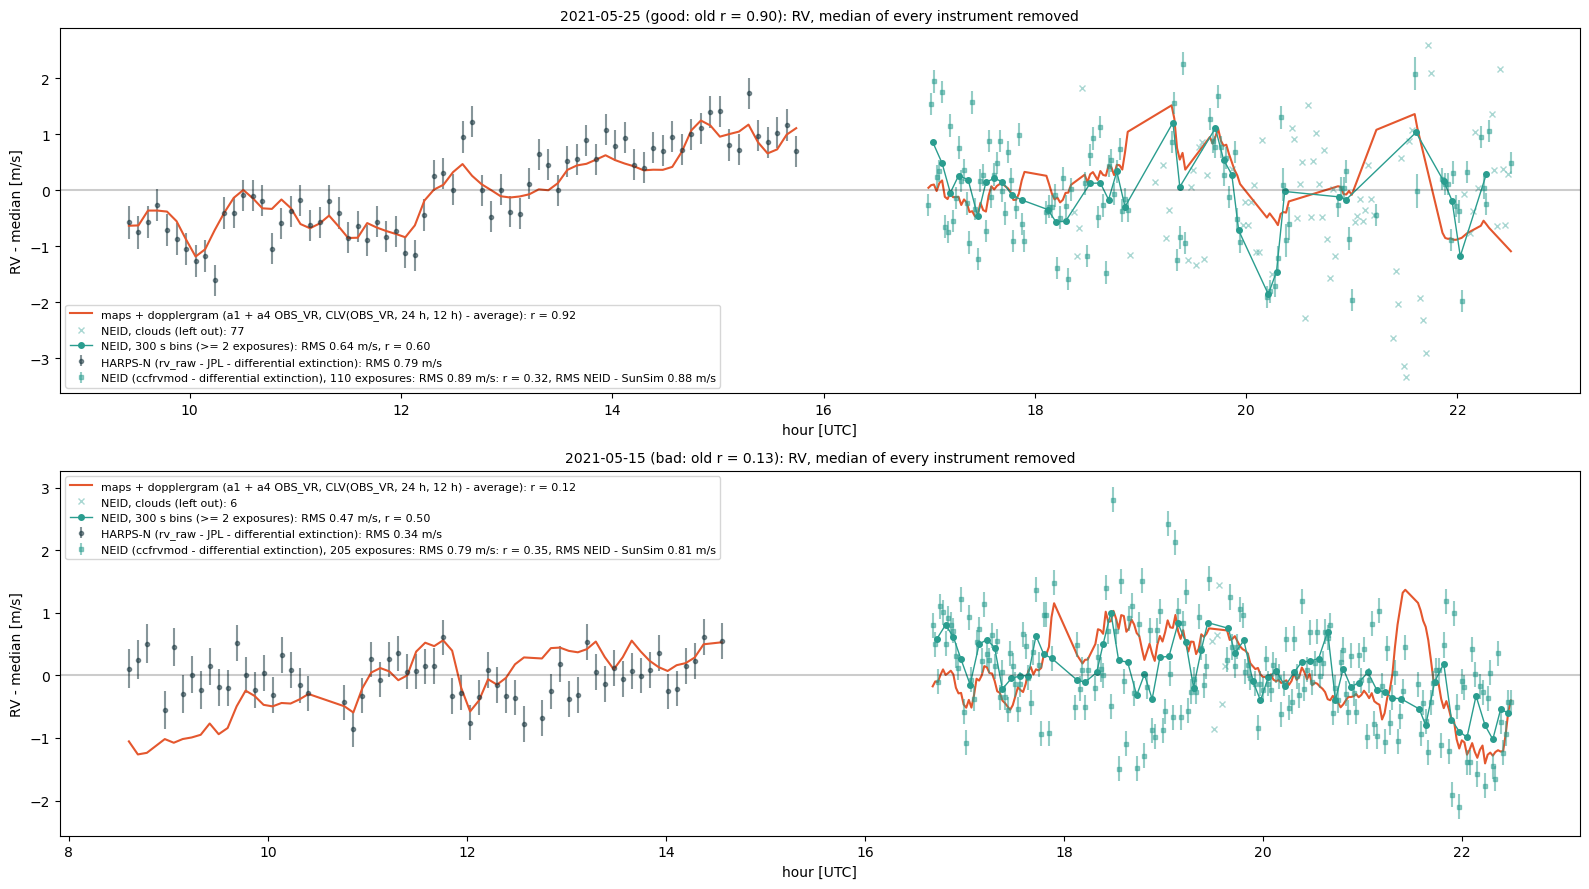

In [21]:
NEID = str(local_path('personal_data') / 'neid_solarl2_2021-05-01_2021-07-01.csv')   # NEID archive (solarl2)
NEID_RESULTS = 'results_2days_rotvr_clv5vr_h2_diffext_snr0.98'   # PIC/supergranulation_haywood_neid.dag
COL['neid'] = '#2a9d8f'
BIN = 300.0                                                 # [s] NEID averaged as one HARPS-N exposure (p modes)
col_h2, name_h2, colour_h2 = MODELS[0]
sim_neid = pd.read_csv(local_path('supergranulation_haywood_neid_results') / NEID_RESULTS / 'exposures.csv')


def bins(jd, *x, width=BIN):
    """Means of x in bins of width s from the first jd (bins with >= 2 values)."""
    k = np.floor((jd - jd[0]) * 86400 / width).astype(int)
    n = np.bincount(k)
    ok = n >= 2
    return [np.bincount(k, v)[ok] / n[ok] for v in x]


fig, axes = plt.subplots(len(DAYS), 1, figsize=(16, 4.5 * len(DAYS)), squeeze=False)
for ax, d in zip(axes[:, 0], DAYS):
    b = both[both['day'] == d]
    h = (b['jd_utc'] + 0.5) % 1 * 24
    o, s = intra(b, 'rv_obs'), intra(b, col_h2)
    ax.errorbar(h, o, yerr=b['rv_err'], fmt='o', ms=3, color=COL['harpsn'], alpha=0.5,
                label='HARPS-N (rv_raw - JPL - differential extinction): RMS %.2f m/s' % np.std(o))
    ax.plot(h, s, '-', color=colour_h2, lw=1.5, label='%s: r = %.2f' % (name_h2, pearsonr(s, o)[0]))
    n = obs.load_neid(NEID, d)
    sd = sim_neid[sim_neid['day'] == d]                      # the NEID exposures simulated on PIC (within 2 s)
    i = np.abs(sd['jd_utc'].values[None, :] - n['jd'][:, None]).argmin(axis=1)
    g = n['good'] & (np.abs(sd['jd_utc'].values[i] - n['jd']) * 86400 < 2)
    sn = sd['rv_maps_dopplergram'].values[i][g]
    sn = sn - np.median(sn)
    hn = (n['jd'] + 0.5) % 1 * 24
    rn = n['rv'] - np.median(n['rv'][g])
    hb, rb, sb = bins(n['jd'][g], hn[g], rn[g], sn)
    ax.plot(hn[g], sn, '-', color=colour_h2, lw=1.5)
    ax.errorbar(hn[g], rn[g], yerr=n['rv_err'][g], fmt='s', ms=3, color=COL['neid'], alpha=0.5,
                label='NEID (ccfrvmod - differential extinction), %d exposures: RMS %.2f m/s: r = %.2f, RMS NEID - SunSim %.2f m/s'
                % (g.sum(), np.std(rn[g]), pearsonr(sn, rn[g])[0], np.std(rn[g] - sn)))
    ax.plot(hn[~n['good']], rn[~n['good']], 'x', ms=4, color=COL['neid'], alpha=0.4,
            label='NEID, clouds (left out): %d' % (~n['good']).sum())
    ax.plot(hb, rb, 'o-', ms=4, lw=1, color=COL['neid'], label='NEID, %.0f s bins (>= 2 exposures): RMS %.2f m/s, r = %.2f'
            % (BIN, np.std(rb), pearsonr(sb, rb)[0]))
    ax.axhline(0, color='k', alpha=0.2)
    ax.set_title('%s (%s): RV, median of every instrument removed' % (d, DAYS[d]), fontsize=10)
    ax.set_xlabel('hour [UTC]'); ax.set_ylabel('RV - median [m/s]')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


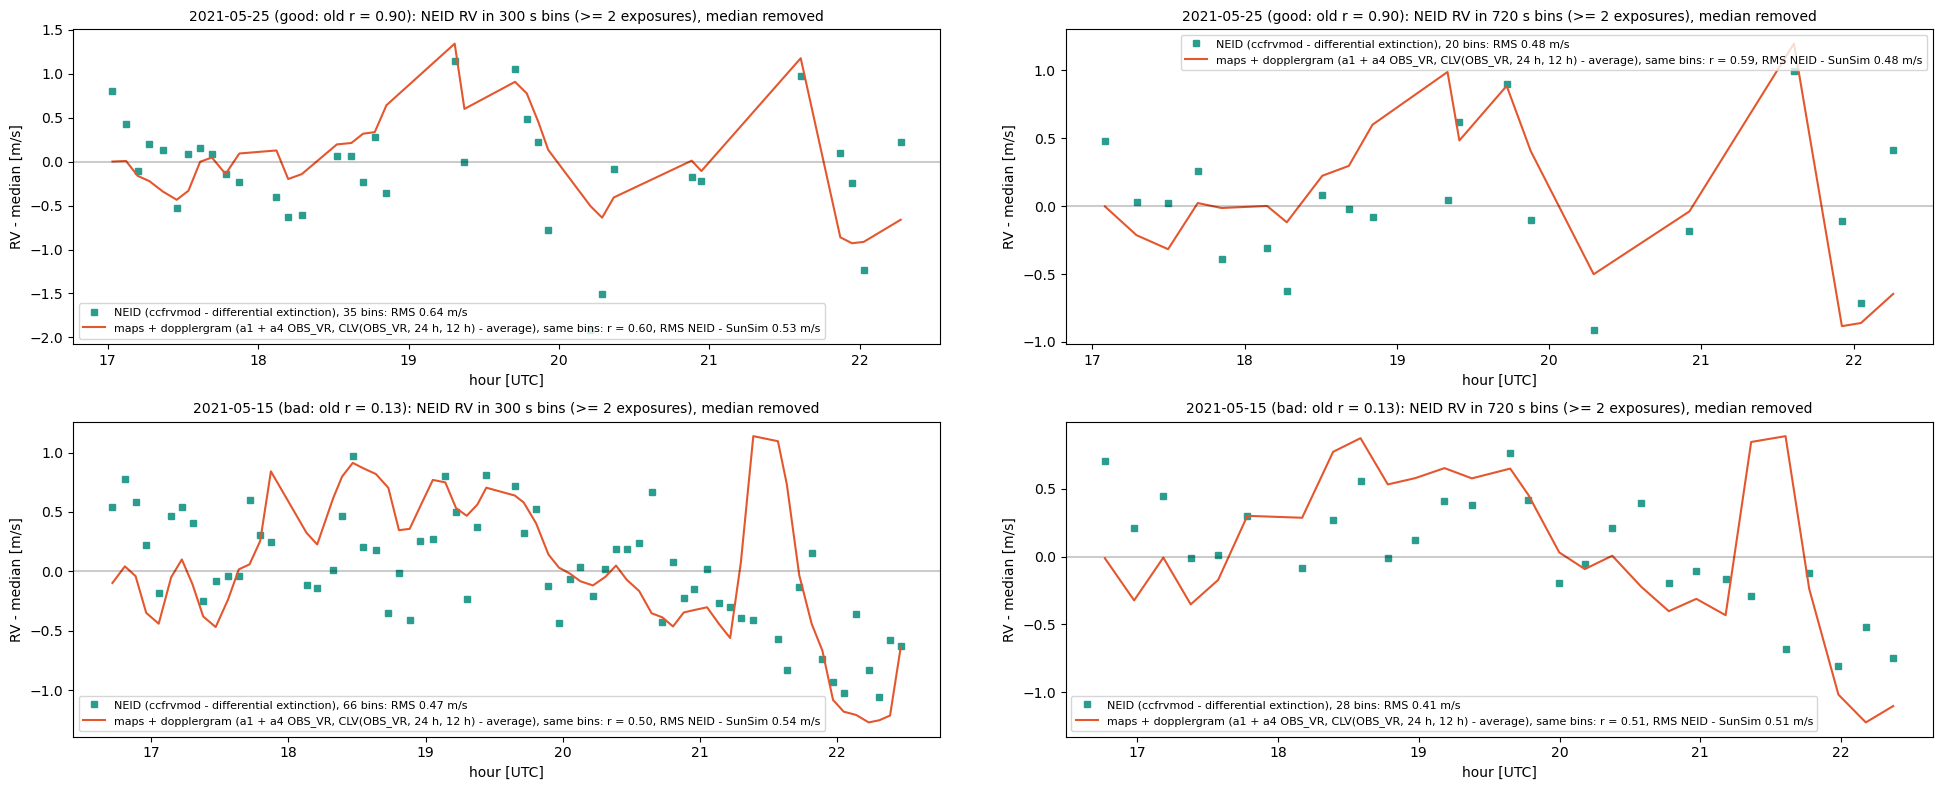

In [22]:
WIDTHS = (BIN, WINDOW)                                      # [s] one HARPS-N exposure, the dopplergram window of SunSim
fig, axes = plt.subplots(len(DAYS), len(WIDTHS), figsize=(10 * len(WIDTHS), 4 * len(DAYS)), squeeze=False)
for row, d in zip(axes, DAYS):
    n = obs.load_neid(NEID, d)
    sd = sim_neid[sim_neid['day'] == d]
    i = np.abs(sd['jd_utc'].values[None, :] - n['jd'][:, None]).argmin(axis=1)
    g = n['good'] & (np.abs(sd['jd_utc'].values[i] - n['jd']) * 86400 < 2)
    sn = sd['rv_maps_dopplergram'].values[i][g]
    for ax, w in zip(row, WIDTHS):
        hb, rb, sb = bins(n['jd'][g], (n['jd'][g] + 0.5) % 1 * 24, n['rv'][g], sn, width=w)
        rb, sb = rb - np.median(rb), sb - np.median(sb)
        ax.plot(hb, rb, 's', ms=4, color=COL['neid'],
                label='NEID (ccfrvmod - differential extinction), %d bins: RMS %.2f m/s' % (len(rb), np.std(rb)))
        ax.plot(hb, sb, '-', color=colour_h2, lw=1.5,
                label='%s, same bins: r = %.2f, RMS NEID - SunSim %.2f m/s' % (name_h2, pearsonr(sb, rb)[0], np.std(rb - sb)))
        ax.axhline(0, color='k', alpha=0.2)
        ax.set_title('%s (%s): NEID RV in %.0f s bins (>= 2 exposures), median removed' % (d, DAYS[d], w), fontsize=10)
        ax.set_xlabel('hour [UTC]'); ax.set_ylabel('RV - median [m/s]')
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()